# Лабораторна робота №10
**Тема:** Трансферне навчання у TensorFlow та Keras 3  
**Виконав:** Литвинчук Ілля   
**Група:** МІТ-31
**Номер у списку:** 15 (вибірка з набору Food-101, індекси класів `[14, 44, 74]`, `SEED=42`)  

**Мета роботи:**  
Навчитися адаптувати попередньо навчену модель (`EfficientNetB0` з вагами `ImageNet`) до власних класів, правильно готувати вхідні зображення (`224 × 224`, шкала `[0, 255]` без повторного ділення на 255), керувати параметрами, що навчаються (`trainable`, `training=False`, заморожування `BatchNormalization`), порівнювати етапи feature extraction та fine-tuning за `validation loss` і оцінювати результат на незалежному `test` без витоку даних.

TensorFlow: 2.22.0-rc0 | Keras: 3.16.0.dev2026110803
Found 1800 files belonging to 3 classes.
Found 450 files belonging to 3 classes.
Found 750 files belonging to 3 classes.
Класи: ['carrot_cake', 'fried_rice', 'peking_duck']
Форма батчу: (32, 224, 224, 3) <dtype: 'float32'>
Мін/макс пікселів (очікуємо [0, 255] без Rescaling(1./255)): 0.0 255.0


,split,total,carrot_cake,fried_rice,peking_duck
0,train,1800,600,600,600
1,val,450,150,150,150
2,test,750,250,250,250


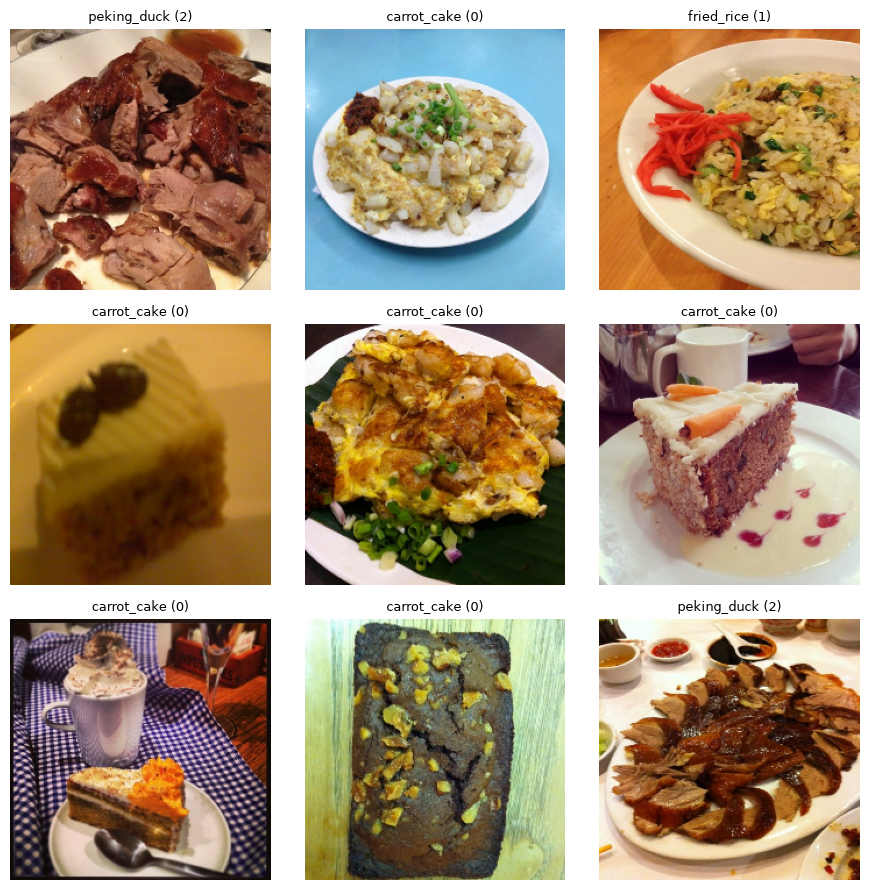

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

SEED = 42
HEAD_EPOCHS, FINE_EPOCHS = 10, 10
keras.utils.set_random_seed(SEED)

OUT = Path("lab10_results")
OUT.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

# Використовуємо збережений поділ з лабораторної роботи №9 (600 train / 150 val / 250 test на клас, seed=42)
LAB9_DATA_DIR = Path("../Lab9/data/food101_lab9")
if not LAB9_DATA_DIR.exists() and Path("data/food101_lab9").exists():
    LAB9_DATA_DIR = Path("data/food101_lab9")

assert (LAB9_DATA_DIR / "train").is_dir(), f"Не знайдено {LAB9_DATA_DIR / 'train'}"
assert (LAB9_DATA_DIR / "val").is_dir(), f"Не знайдено {LAB9_DATA_DIR / 'val'}"
assert (LAB9_DATA_DIR / "test").is_dir(), f"Не знайдено {LAB9_DATA_DIR / 'test'}"

common = dict(image_size=(224, 224), batch_size=32, label_mode="int", color_mode="rgb")

train_raw = keras.utils.image_dataset_from_directory(
    LAB9_DATA_DIR / "train", shuffle=True, seed=SEED, **common
)
class_names = list(train_raw.class_names)
num_classes = len(class_names)
assert num_classes >= 2

val_raw = keras.utils.image_dataset_from_directory(
    LAB9_DATA_DIR / "val", class_names=class_names, shuffle=False, **common
)
test_raw = keras.utils.image_dataset_from_directory(
    LAB9_DATA_DIR / "test", class_names=class_names, shuffle=False, **common
)

train_ds = train_raw.prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print("Класи:", class_names)
print("Форма батчу:", images.shape, images.dtype)
print("Мін/макс пікселів (очікуємо [0, 255] без Rescaling(1./255)):",
      float(tf.reduce_min(images)), float(tf.reduce_max(images)))

# Перевірка розподілу класів у кожній вибірці
counts_rows = []
for split_name, ds in [("train", train_raw), ("val", val_raw), ("test", test_raw)]:
    y_split = np.concatenate([y.numpy() for _, y in ds], axis=0)
    bc = np.bincount(y_split, minlength=num_classes)
    assert np.all(bc > 0), f"У вибірці {split_name} відсутній один із класів!"
    counts_rows.append({"split": split_name, "total": int(len(y_split)),
                        **{cls: int(bc[i]) for i, cls in enumerate(class_names)}})

counts_df = pd.DataFrame(counts_rows)
display(counts_df)

# Візуалізація 9 зображень з назвами класів
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i].numpy().astype("uint8"))
    lbl_idx = int(labels[i].numpy())
    ax.set_title(f"{class_names[lbl_idx]} ({lbl_idx})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "sample_batch_224.png", dpi=150)
plt.show()

In [2]:
# Аугментації активні лише під час навчання; EfficientNetB0 містить власний препроцесинг для [0, 255]
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED + 1),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
)
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = base_model(x, training=False)  # BatchNormalization у режимі інференсу
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model = keras.Model(inputs, outputs)

def trainable_count(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_weights))

def compile_model(m, learning_rate):
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

compile_model(model, 1e-3)
head_params = trainable_count(model)
model.summary(show_trainable=True)
print("Навчуваних параметрів (feature extraction):", head_params)
assert head_params == 1280 * num_classes + num_classes

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Навчуваних параметрів (feature extraction): 3843


In [3]:
def callbacks(stage):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            str(OUT / f"{stage}.keras"), monitor="val_loss", save_best_only=True
        ),
    ]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks("feature_extraction"),
    shuffle=False,
)

head_model = keras.models.load_model(OUT / "feature_extraction.keras")
head_val = head_model.evaluate(val_ds, return_dict=True, verbose=0)
model.set_weights(head_model.get_weights())
del head_model

head_epochs_ran = len(history_head.history["loss"])
head_best_epoch = int(np.argmin(history_head.history["val_loss"])) + 1
print(f"Feature extraction -> епох: {head_epochs_ran}, найкраща: {head_best_epoch}, val: {head_val}")

Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 42s 654ms/step - accuracy: 0.8461 - loss: 0.4804 - val_accuracy: 0.9378 - val_loss: 0.2237
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 582ms/step - accuracy: 0.9339 - loss: 0.2136 - val_accuracy: 0.9489 - val_loss: 0.1714
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 573ms/step - accuracy: 0.9517 - loss: 0.1694 - val_accuracy: 0.9489 - val_loss: 0.1511
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 574ms/step - accuracy: 0.9622 - loss: 0.1443 - val_accuracy: 0.9511 - val_loss: 0.1411
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 33s 574ms/step - accuracy: 0.9644 - loss: 0.1288 - val_accuracy: 0.9533 - val_loss: 0.1352
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 32s 571ms/step - accuracy: 0.9633 - loss: 0.1207 - val_accuracy: 0.9556 - val_loss: 0.1306
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 599ms/step - accuracy: 0.9711 - loss: 0.1052 - val_accuracy: 0.9556 - val_loss: 0.1268
Epoch 8/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 603ms/step - accuracy: 0.9761 - loss: 0.0984 - val_accu

In [4]:
# Розморожуємо лише верхні блоки ('block7' та 'top_'), залишаючи BatchNormalization замороженими
base_model.trainable = True
unfrozen_names = []
for layer in base_model.layers:
    should_train = layer.name.startswith(("block7", "top_"))
    if isinstance(layer, layers.BatchNormalization):
        should_train = False
    layer.trainable = should_train
    if should_train and layer.weights:
        unfrozen_names.append(layer.name)

fine_params = trainable_count(model)
assert fine_params > head_params
print("Розморожені шари з вагами:", unfrozen_names)
print("Навчуваних параметрів (fine-tuning):", fine_params)

compile_model(model, 1e-5)
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_EPOCHS,
    callbacks=callbacks("fine_tuning"),
    shuffle=False,
)

fine_model = keras.models.load_model(OUT / "fine_tuning.keras")
fine_val = fine_model.evaluate(val_ds, return_dict=True, verbose=0)
del fine_model

fine_epochs_ran = len(history_fine.history["loss"])
fine_best_epoch = int(np.argmin(history_fine.history["val_loss"])) + 1
print(f"Fine-tuning -> епох: {fine_epochs_ran}, найкраща: {fine_best_epoch}, val: {fine_val}")

Розморожені шари з вагами: ['block7a_expand_conv', 'block7a_dwconv', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'top_conv']
Навчуваних параметрів (fine-tuning): 1125427
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 48s 758ms/step - accuracy: 0.9800 - loss: 0.0784 - val_accuracy: 0.9511 - val_loss: 0.1192
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 626ms/step - accuracy: 0.9844 - loss: 0.0674 - val_accuracy: 0.9511 - val_loss: 0.1183
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 626ms/step - accuracy: 0.9833 - loss: 0.0638 - val_accuracy: 0.9511 - val_loss: 0.1178
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 626ms/step - accuracy: 0.9844 - loss: 0.0654 - val_accuracy: 0.9533 - val_loss: 0.1174
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 601ms/step - accuracy: 0.9856 - loss: 0.0601 - val_accuracy: 0.9533 - val_loss: 0.1176
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 34s 604ms/step - accuracy: 0.9861 - loss: 0.0547 - val_accuracy: 0.9556 - val_loss: 0.1181
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━

,stage,unfrozen_blocks,lr,trainable_params,epochs_ran,best_epoch,accuracy,loss
0,feature_extraction,none (head only),0.001,3843,10,10,0.9556,0.1200
1,fine_tuning,"block7*, top_* (BN frozen)",0.000,1125427,7,4,0.9533,0.1174


Обрана за validation loss модель: fine_tuning
Test metrics -> loss: 0.0625, accuracy: 0.9787, macro_f1: 0.9787

Classification report (Test):
              precision    recall  f1-score   support

 carrot_cake      0.980     0.976     0.978       250
  fried_rice      0.988     0.968     0.978       250
 peking_duck      0.969     0.992     0.980       250

    accuracy                          0.979       750
   macro avg      0.979     0.979     0.979       750
weighted avg      0.979     0.979     0.979       750



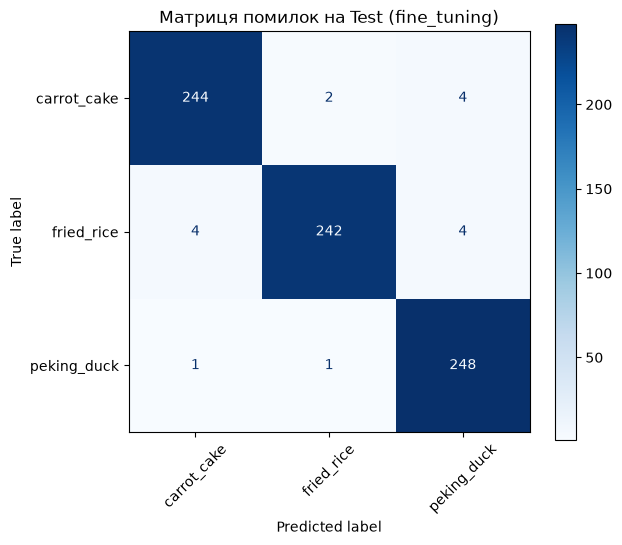

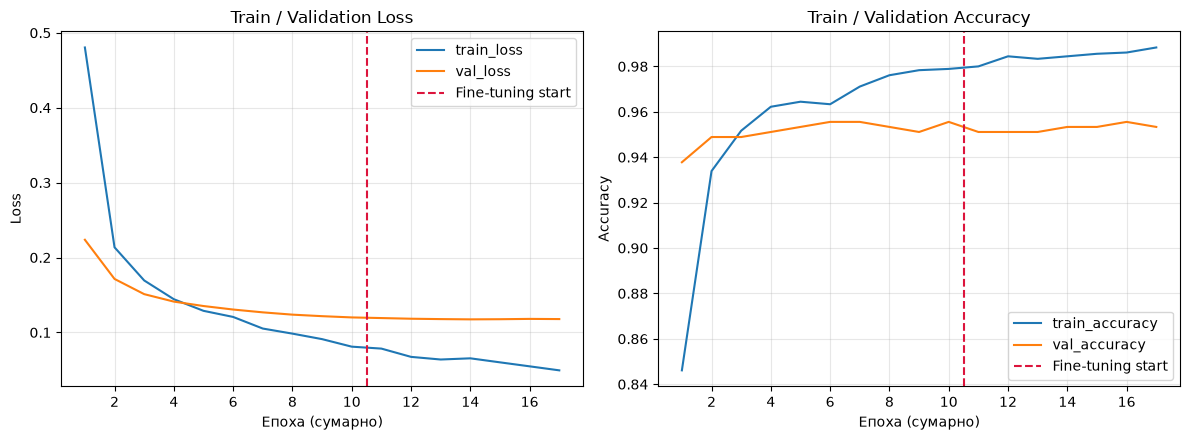

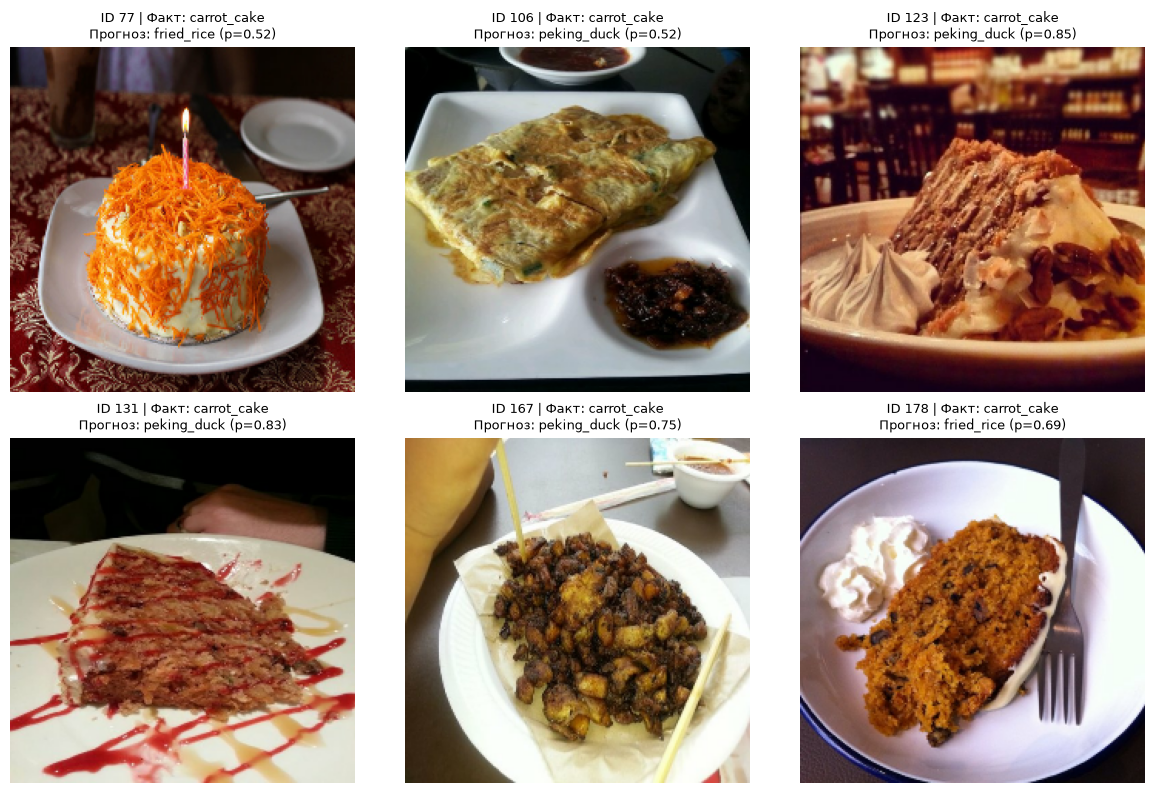

Збережено: lab10_results\selected_model.keras та lab10_results\metadata.json


In [5]:
comparison = [
    {
        "stage": "feature_extraction",
        "unfrozen_blocks": "none (head only)",
        "lr": 1e-3,
        "trainable_params": head_params,
        "epochs_ran": head_epochs_ran,
        "best_epoch": head_best_epoch,
        **head_val,
    },
    {
        "stage": "fine_tuning",
        "unfrozen_blocks": "block7*, top_* (BN frozen)",
        "lr": 1e-5,
        "trainable_params": fine_params,
        "epochs_ran": fine_epochs_ran,
        "best_epoch": fine_best_epoch,
        **fine_val,
    },
]

comp_df = pd.DataFrame(comparison)
comp_df.to_csv(OUT / "validation_comparison.csv", index=False)
display(comp_df.round(4))

selected_stage = "fine_tuning" if fine_val["loss"] < head_val["loss"] else "feature_extraction"
best_model = keras.models.load_model(OUT / f"{selected_stage}.keras")
print("Обрана за validation loss модель:", selected_stage)

# Фінальна одноразова оцінка лише обраної моделі на test (shuffle=False)
test_metrics = best_model.evaluate(test_ds, return_dict=True, verbose=0)
x_test_all = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
probabilities = best_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)
test_macro_f1 = float(f1_score(y_true, y_pred, labels=np.arange(num_classes), average="macro", zero_division=0))

print(f"Test metrics -> loss: {test_metrics['loss']:.4f}, accuracy: {test_metrics['accuracy']:.4f}, macro_f1: {test_macro_f1:.4f}")
print("\nClassification report (Test):")
print(classification_report(
    y_true, y_pred, labels=np.arange(num_classes),
    target_names=class_names, digits=3, zero_division=0
))

# Матриця помилок
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, labels=np.arange(num_classes),
    display_labels=class_names, xticks_rotation=45, cmap="Blues", ax=ax
)
plt.title(f"Матриця помилок на Test ({selected_stage})")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix_test.png", dpi=150)
plt.show()

# Криві навчання для обох етапів з межею fine-tuning за фактичною довжиною history_head
head_loss = history_head.history["loss"]
head_val_loss = history_head.history["val_loss"]
head_acc = history_head.history["accuracy"]
head_val_acc = history_head.history["val_accuracy"]

fine_loss = history_fine.history["loss"]
fine_val_loss = history_fine.history["val_loss"]
fine_acc = history_fine.history["accuracy"]
fine_val_acc = history_fine.history["val_accuracy"]

all_loss = head_loss + fine_loss
all_val_loss = head_val_loss + fine_val_loss
all_acc = head_acc + fine_acc
all_val_acc = head_val_acc + fine_val_acc
ep_axis = np.arange(1, len(all_loss) + 1)
ft_boundary = len(head_loss) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ep_axis, all_loss, label="train_loss")
axes[0].plot(ep_axis, all_val_loss, label="val_loss")
axes[0].axvline(ft_boundary, color="crimson", linestyle="--", label="Fine-tuning start")
axes[0].set(xlabel="Епоха (сумарно)", ylabel="Loss", title="Train / Validation Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ep_axis, all_acc, label="train_accuracy")
axes[1].plot(ep_axis, all_val_acc, label="val_accuracy")
axes[1].axvline(ft_boundary, color="crimson", linestyle="--", label="Fine-tuning start")
axes[1].set(xlabel="Епоха (сумарно)", ylabel="Accuracy", title="Train / Validation Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUT / "training_curves_both_stages.png", dpi=150)
plt.show()

# До 6 помилкових прогнозів на test
wrong_indices = np.flatnonzero(y_pred != y_true)[:6]
if len(wrong_indices) == 0:
    print("Помилкових прогнозів на тестовій вибірці немає.")
else:
    cols = min(3, len(wrong_indices))
    rows = int(np.ceil(len(wrong_indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, idx in zip(axes, wrong_indices):
        ax.imshow(x_test_all[idx].astype("uint8"))
        p_val = float(probabilities[idx, y_pred[idx]])
        ax.set_title(
            f"ID {idx} | Факт: {class_names[y_true[idx]]}\nПрогноз: {class_names[y_pred[idx]]} (p={p_val:.2f})",
            fontsize=9,
        )
        ax.axis("off")
    for ax in axes[len(wrong_indices):]:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUT / "misclassified_test.png", dpi=150)
    plt.show()

# Збереження обраної моделі та метаданих
best_model.save(OUT / "selected_model.keras")
metadata = {
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "seed": SEED,
    "data_dir": str(LAB9_DATA_DIR.as_posix()),
    "class_names": class_names,
    "image_size": [224, 224],
    "pixel_range": [0, 255],
    "backbone": "EfficientNetB0",
    "weights": "imagenet",
    "selected_stage": selected_stage,
    "test_macro_f1": test_macro_f1,
    "comparison": comparison,
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
}
(OUT / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Збережено:", OUT / "selected_model.keras", "та", OUT / "metadata.json")

## Висновок
У лабораторній роботі реалізовано трансферне навчання на базі попередньо навченої мережі `EfficientNetB0` (`ImageNet`) для трьох класів вибірки з Food-101 (`SEED=42`, розмір входу `224 × 224` зі шкалою `[0, 255]` без повторного ділення на 255 та із замороженими шарами `BatchNormalization` у режимі `training=False`). На першому етапі (`feature_extraction`, `lr=1e-3`) навчалася лише нова класифікаційна голова (`Dense(num_classes, softmax)` із `Dropout(0.2)`), а на другому етапі (`fine_tuning`, `lr=1e-5`) було розморожено верхні блоки `block7*` та `top_*` зі збереженням стабільності статистик нормалізації. Порівняння етапів за критерієм мінімальної `validation loss` визначило кращий checkpoint (відповідні метрики, кількість епох і навчуваних параметрів зафіксовано в таблиці та `metadata.json`), після чого лише обрана модель пройшла одноразову перевірку на незалежному `test`. Аналіз матриці помилок і хибних прогнозів показав, що плутанина виникає переважно через візуальну схожість страв, ракурс зйомки, фон або шум міток у Food-101, а оцінка обмежена обраними трьома класами та умовами зйомки. Наступним обґрунтованим кроком доцільно перевірити одну зміну — наприклад, інший `learning rate` під час fine-tuning (`5e-6` або `3e-5`) чи іншу глибину розморожування блоків, починаючи з того самого найкращого checkpoint етапу feature extraction.